# Flujo incompresible con Navier–Stokes: la cavidad con tapa móvil

**FEM-sim · cuaderno de ejemplo paso a paso**

Este cuaderno monta, resuelve, verifica e interpreta un problema de **flujo laminar incompresible** con la física `ff`
(`Source/Physics/FluidFlow.py`) en su modo Navier–Stokes. El caso es la **cavidad cuadrada con tapa móvil**, el problema de
referencia más usado para validar códigos de fluidos: geometría trivial, física rica (vórtices, capas límite, esquinas
singulares) y resultados de referencia publicados.

**Qué vas a encontrar:**

| Sección | Contenido |
|---|---|
| 1 | El problema físico, las ecuaciones y el número de Reynolds |
| 2–4 | Entorno, parámetros y malla |
| 5–7 | El modelo: campos, propiedades, condiciones de contorno y configuración del solver |
| 8 | **Qué ocurre internamente**: grados de libertad, el `System`, la estructura por bloques del jacobiano, la estabilización y el lazo de Newton |
| 9–10 | Solución a Re = 100 y sus resultados: velocidad, presión, vorticidad, función de corriente y comparación con la literatura |
| 11 | Continuación a Re = 400 y 1000 |
| 12 | Verificación con una solución exacta (flujo de Kovasznay): orden de convergencia |
| 13 | **Presentación de resultados**: resumen, figura de síntesis, conclusiones y límites |
| 14 | Exportación a ParaView |

Cada celda de código es ejecutable en orden. El cuaderno completo tarda menos de un minuto.

## 1. El problema físico

Un fluido llena una cavidad cuadrada de lado $L = 1$. La **tapa superior se desliza** hacia la derecha con velocidad
$U = 1$ y arrastra al fluido por fricción viscosa; las otras tres paredes están quietas. El fluido no puede salir, así que
recircula: se forma un **vórtice principal** y, a medida que aumenta la inercia, **vórtices secundarios** en las esquinas
inferiores.

**Incógnitas** (en cada punto): la velocidad $\mathbf{u} = (u, v)$ y la presión $p$.

**Ecuaciones de Navier–Stokes incompresibles (estacionarias):**

$$
\rho\,(\mathbf{u}\cdot\nabla)\,\mathbf{u} \;-\; \nabla\cdot\big(2\mu\,\boldsymbol{\varepsilon}(\mathbf{u})\big) \;+\; \nabla p \;=\; \mathbf{f},
\qquad \nabla\cdot\mathbf{u} = 0,
\qquad \boldsymbol{\varepsilon}(\mathbf{u}) = \tfrac12\big(\nabla\mathbf{u} + \nabla\mathbf{u}^{T}\big)
$$

| Término | Significado físico |
|---|---|
| $\rho(\mathbf{u}\cdot\nabla)\mathbf{u}$ | **Inercia** (aceleración convectiva). Es el término no lineal |
| $\nabla\cdot(2\mu\boldsymbol\varepsilon)$ | Fuerzas **viscosas** (difusión de cantidad de movimiento) |
| $\nabla p$ | Fuerza de **presión**. En flujo incompresible $p$ no tiene ecuación propia: es el multiplicador que hace cumplir $\nabla\cdot\mathbf{u} = 0$ |
| $\nabla\cdot\mathbf{u} = 0$ | **Conservación de la masa** (incompresibilidad) |

**Número de Reynolds.** Con $\rho$, $U$, $L$ y $\mu$ el problema depende de un solo parámetro adimensional,

$$\mathrm{Re} = \frac{\rho\, U\, L}{\mu} = \frac{\text{fuerzas de inercia}}{\text{fuerzas viscosas}}.$$

Con $\rho = U = L = 1$, basta elegir $\mu = 1/\mathrm{Re}$. A Re bajo (≲ 1) domina la viscosidad (flujo reptante, simétrico);
a Re alto la inercia desplaza el vórtice y aparecen capas límite delgadas, que exigen estabilización numérica.

**Qué se evalúa en este cuaderno:**
1. Que el modelo reproduce los perfiles de velocidad de referencia de **Ghia, Ghia y Shin (1982)** a Re = 100, 400 y 1000.
2. Que el método converge con el orden esperado frente a una **solución exacta** (Kovasznay, 1948).
3. Cómo se comporta el solver de Newton (iteraciones, convergencia) y qué hace la estabilización.

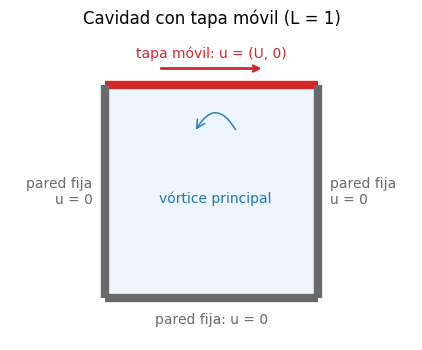

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.add_patch(patches.Rectangle((0, 0), 1, 1, facecolor='#eef4fb', edgecolor='none'))
ax.plot([0, 1], [1, 1], color='tab:red', lw=6, solid_capstyle='butt')
for xs, ys in (([0, 0], [0, 1]), ([1, 1], [0, 1]), ([0, 1], [0, 0])):
    ax.plot(xs, ys, color='dimgray', lw=6, solid_capstyle='butt')
ax.annotate('', xy=(0.75, 1.08), xytext=(0.25, 1.08), arrowprops=dict(arrowstyle='->', color='tab:red', lw=2))
ax.text(0.5, 1.13, 'tapa móvil: u = (U, 0)', ha='center', color='tab:red')
ax.text(-0.06, 0.5, 'pared fija\nu = 0', ha='right', va='center', color='dimgray')
ax.text(1.06, 0.5, 'pared fija\nu = 0', ha='left', va='center', color='dimgray')
ax.text(0.5, -0.07, 'pared fija: u = 0', ha='center', va='top', color='dimgray')
circle = patches.FancyArrowPatch((0.62, 0.78), (0.42, 0.78), connectionstyle='arc3,rad=0.9',
                                 arrowstyle='->', mutation_scale=15, color='tab:blue')
ax.add_patch(circle)
ax.text(0.52, 0.45, 'vórtice principal', ha='center', color='tab:blue')
ax.set_xlim(-0.45, 1.45); ax.set_ylim(-0.2, 1.25); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Cavidad con tapa móvil (L = 1)')
plt.show()

## 2. Preparación del entorno

| Módulo | Para qué sirve |
|---|---|
| `Mesh` | Genera la malla (nodos y elementos) y selecciona bordes del contorno |
| `Model` | Reúne malla, material y física; es el punto de entrada para configurar y resolver |
| `material` | Guarda propiedades (`miu` = viscosidad dinámica, `rho` = densidad, ...) |
| `ff` | Física de **flujo incompresible**: Stokes por defecto, Navier–Stokes con `setInertia(True)` |
| `ht` | Física de calor. Aquí se reutiliza como **resolvedor de Poisson** para la función de corriente |
| `ops` | Operadores de la forma débil (para inspeccionar la estabilización) |
| `enums` | Opciones del solver: tipo de estudio, de problema y de solver lineal |

El registro de la simulación (`sim_logger`) escribe cada paso en `Logs/`; en pantalla se dejan solo los avisos.

In [2]:
import os, sys, time, logging
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.tri as mtri

sys.path.insert(0, os.getcwd())          # el cuaderno vive en la raíz del proyecto
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.HeatTransfer import ht
import Source.Simulation.Operators as ops
from Source.enums import ElementType, StudyType, ProblemType, SolverType, DirectSolvers
from Source.logger_config import sim_logger

for handler in sim_logger.handlers:                     # solo avisos en pantalla; el detalle sigue en Logs/
    if not isinstance(handler, logging.FileHandler):
        handler.setLevel(logging.WARNING)

print("Módulos importados. Directorio de trabajo:", os.getcwd())

Módulos importados. Directorio de trabajo: D:\Documentos\Python Scripts\FEM-sim


## 3. Parámetros

| Símbolo | Variable | Valor | Significado |
|---|---|---|---|
| $L$ | `L` | 1 | Lado de la cavidad |
| $U$ | `U_lid` | 1 | Velocidad de la tapa |
| $\rho$ | `rho` | 1 | Densidad |
| $\mathrm{Re}$ | `Re` | 100 | Reynolds del primer cálculo. Después se sube a 400 y 1000 |
| $\mu$ | `mu` | $\rho U L/\mathrm{Re}$ | Viscosidad dinámica que da ese Reynolds |
| $n$ | `n` | 64 | Elementos por lado (malla de $64 \times 64$) |

Los datos de referencia de Ghia et al. (1982) se tabulan abajo: $u$ a lo largo de la línea vertical central ($x = 0.5$) y $v$ a
lo largo de la horizontal ($y = 0.5$), además del centro del vórtice principal. Ghia usó una malla de diferencias finitas de
$129 \times 129$ (y $257 \times 257$ a Re alto); sus valores son una referencia con incertidumbre del orden del 1 %.

In [3]:
L, U_lid, rho = 1.0, 1.0, 1.0
Re = 100.0
mu = rho * U_lid * L / Re
n = 64

# Ghia, Ghia & Shin (1982), Re = 100
GHIA_U = np.array([[1.0000, 1.00000], [0.9766, 0.84123], [0.9688, 0.78871], [0.9609, 0.73722], [0.9531, 0.68717],
                   [0.8516, 0.23151], [0.7344, 0.00332], [0.6172, -0.13641], [0.5000, -0.20581], [0.4531, -0.21090],
                   [0.2813, -0.15662], [0.1719, -0.10150], [0.1016, -0.06434], [0.0703, -0.04775], [0.0625, -0.04192],
                   [0.0547, -0.03717], [0.0000, 0.00000]])            # columnas: y, u(0.5, y)
GHIA_V = np.array([[1.0000, 0.00000], [0.9688, -0.05906], [0.9609, -0.07391], [0.9531, -0.08864], [0.9453, -0.10313],
                   [0.9063, -0.16914], [0.8594, -0.22445], [0.8047, -0.24533], [0.5000, 0.05454], [0.2344, 0.17527],
                   [0.2266, 0.17507], [0.1563, 0.16077], [0.0938, 0.12317], [0.0781, 0.10890], [0.0703, 0.10091],
                   [0.0625, 0.09233], [0.0000, 0.00000]])            # columnas: x, v(x, 0.5)
# Centro del vórtice principal (x, y, psi) según Ghia et al.
GHIA_VORTEX = {100.0: (0.6172, 0.7344, -0.103423), 400.0: (0.5547, 0.6055, -0.113909), 1000.0: (0.5313, 0.5625, -0.117929)}

print(f"Re = {Re:.0f}  ->  mu = {mu:.4g} Pa·s (con rho = U = L = 1)")

Re = 100  ->  mu = 0.01 Pa·s (con rho = U = L = 1)


## 4. La malla

Se usan **cuadriláteros bilineales (Q4)**: `generate2DMesh((L, L), (n, n), ElementType.quadrilateral)` crea $n \times n$
elementos, numera los nodos a lo largo de $x$ primero y lista cada elemento en sentido antihorario.

Las condiciones de contorno se asignan a **bordes**: `mesh.boundary_edges(predicado)` devuelve las aristas del contorno cuyo
punto medio $(x, y)$ cumple el predicado. Cada arista es un par de nodos.

> **Esquinas superiores.** Los dos nodos de las esquinas de la tapa pertenecen a la vez a la tapa y a una pared vertical. La
> velocidad allí es discontinua (salta de $U$ a $0$): es una **singularidad** del problema. Aquí se asigna primero la tapa y
> después las paredes, de modo que las esquinas quedan con $\mathbf{u} = 0$ (variante "estanca", la más habitual).

In [4]:
mesh = Mesh()
mesh.generate2DMesh((L, L), (n, n), ElementType.quadrilateral)
xy = np.array([node.coor for node in mesh.NL])

lid = mesh.boundary_edges(lambda x, y: y > L - 1e-9)
walls = mesh.boundary_edges(lambda x, y: y < 1e-9 or x < 1e-9 or x > L - 1e-9)

print(f"Nodos: {mesh.getNoN()}   Elementos: {mesh.getNoE()}   Tamaño de elemento h = {L / n:.4f}")
print(f"Bordes de la tapa: {len(lid)} (por ejemplo {lid[:3]})")
print(f"Bordes de las paredes: {len(walls)}")

Nodos: 4225   Elementos: 4096   Tamaño de elemento h = 0.0156
Bordes de la tapa: 64 (por ejemplo [(4161, 4160), (4162, 4161), (4163, 4162)])
Bordes de las paredes: 192


## 5. El modelo y la física de flujo

`Model(name, dim, mesh, mat, psc=ff)` crea el modelo. Al instanciarse, la física `ff`:

1. Declara **dos campos en los mismos nodos**: `u`, un `vectorField` de 2 componentes, y `p`, un `scalarField`.
   Usar el mismo orden de interpolación para velocidad y presión (Q1/Q1) es cómodo pero **no es estable** por sí solo; la
   física lo corrige con estabilización (sección 8).
2. Lee del material la viscosidad `miu` y la densidad `rho`.

Después se activa la inercia:

| Llamada | Qué hace |
|---|---|
| `setInertia(True, linearization='newton')` | Añade el término $\rho(\mathbf{u}\cdot\nabla)\mathbf{u}$ y la estabilización SUPG/PSPG/LSIC. El problema pasa a ser **no lineal**. `'newton'` usa la tangente completa de la convección (convergencia rápida); `'picard'` usa $\mathbf{u}_{old}\cdot\nabla\mathbf{u}$ (más robusto lejos de la solución, más lento) |
| `setViscosity(mu)` | Cambia $\mu$ (lo usaremos para subir el Reynolds) |
| `viscous_projection` (atributo, `True` por defecto) | Incluye el esfuerzo viscoso **recuperado** en el residuo de la estabilización, para que sea consistente con elementos lineales |
| `setBodyForce(f)` / `setGravity(g)` | Fuerzas de volumen (aquí no hay) |

Sin `setInertia` la física resuelve **Stokes** (flujo reptante), el caso típico de polímeros fundidos.

In [5]:
model = Model(name='cavidad', dim=2, mesh=mesh, mat=material('fluido', miu=mu, rho=rho), psc=ff)
flow = model.physics
flow.setInertia(True, linearization='newton')

print("Física:", flow.physics_description, f"  ({mesh.getNoN()} nodos, {mesh.getNoE()} elementos)")
print("Campos:", {name: type(field).__name__ for name, field in flow.var.items()})
print("Componentes de u:", flow.var['u'].ncomp, "  forma de los valores:", flow.var['u'].values.shape)
print("mu =", flow.mu, "  rho =", flow.rho, "  inercia:", flow.inertia, "  linealización:", flow.linearization)

Física: Laminar flow (Navier-Stokes)   (4225 nodos, 4096 elementos)
Campos: {'u': 'vectorField', 'p': 'scalarField'}
Componentes de u: 2   forma de los valores: (4225, 2)
mu = 0.01   rho = 1.0   inercia: True   linealización: newton


## 6. Condiciones de contorno

| Llamada | Qué impone |
|---|---|
| `addBC_VelocityEdges(bordes, (U, 0))` | Velocidad en los nodos de los bordes. Acepta un vector o una función $u(x, y)$ (perfiles de entrada). Una componente `None` queda libre |
| `addBC_NoSlipEdges(bordes)` | No deslizamiento: $\mathbf{u} = 0$ |
| `addBC_SymmetryEdges(bordes)` | Plano de simetría o pared deslizante: solo $u_n = 0$ |
| `addBC_OutletEdges(bordes, p)` | Salida: tracción normal $-p\,\mathbf{n}$ y flujo desarrollado |
| `addBC_TractionEdges(bordes, t)` | Tracción general $\boldsymbol\sigma\cdot\mathbf{n} = \mathbf{t}$ |

Las condiciones de velocidad se guardan en cada nodo (`node.BC['u']`) como una lista con un valor por componente; se aplican
al construir el sistema, como filas identidad.

**Nivel de la presión.** En flujo incompresible la presión solo aparece como gradiente: $p$ y $p + C$ son igualmente
solución. Una salida o una tracción fijan ese nivel; en la cavidad **todo el contorno tiene velocidad prescrita**, así que la
física fija automáticamente $p = 0$ en el nodo 0 (se puede elegir otro punto con `setPressureReference`). Esto requiere que
el caudal neto del contorno sea cero, cosa que aquí se cumple exactamente porque la tapa es tangente a sí misma.

In [6]:
flow.addBC_VelocityEdges(lid, (U_lid, 0.0))      # primero la tapa ...
flow.addBC_NoSlipEdges(walls)                    # ... después las paredes: las esquinas quedan con u = 0

corner = n                                       # nodo de la esquina superior izquierda: (0, 1)
top_mid = n * (n + 1) + n // 2                   # nodo en el centro de la tapa
print("Tapa, nodo", top_mid, mesh.NL[top_mid].coor, "->", mesh.NL[top_mid].BC['u'])
print("Esquina, nodo", n * (n + 1), mesh.NL[n * (n + 1)].coor, "->", mesh.NL[n * (n + 1)].BC['u'])
print("¿Algún contorno fija el nivel de presión?", flow._pressure_level_set(model), "-> se fija p = 0 en el nodo 0")

Tapa, nodo 4192 (0.5, 1.0) -> {'type': 'Dirichlet', 'value': [1.0, 0.0]}
Esquina, nodo 4160 (0.0, 1.0) -> {'type': 'Dirichlet', 'value': [0.0, 0.0]}
¿Algún contorno fija el nivel de presión? False -> se fija p = 0 en el nodo 0


## 7. Configuración del solver

| Parámetro | Valor | Significado |
|---|---|---|
| `Study` | `StudyType.steady_state` | Estacionario (el transitorio usa el θ-método) |
| `Type` | `ProblemType.nonlinear` | Activa el solver de **Newton–Raphson con búsqueda de línea**. Obligatorio con inercia |
| `Method` | `SolverType.direct` | Resolver cada sistema lineal de forma directa |
| `Solver` | `DirectSolvers.PARDISO` | Factorización LU dispersa paralela (Intel MKL) |

El solver de Newton se detiene cuando el residuo, **escalado fila a fila** con la diagonal del jacobiano inicial, baja 10
órdenes de magnitud ($10^{-10}$ relativo) o queda por debajo de $10^{-10}$ en valor absoluto.

In [7]:
model.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear,
                          Method=SolverType.direct, Solver=DirectSolvers.PARDISO)
print(model.solverOptions)

{'Study': <StudyType.steady_state: 'Steady state'>, 'Type': <ProblemType.nonlinear: 'Nonlinear'>, 'Method': <SolverType.direct: 'Direct'>, 'Solver': <DirectSolvers.PARDISO: 'PARDISO (Parallel Direct Sparse Solver)'>, 'Preconditioner': <Preconditioners.iLU: 'iLU Factorization'>, 'Time Discretization': 1, 'Time Step': 0.05, 'Time': 3, 'Tolerance': 1e-10, 'Max Iterations': None}


## 8. Qué ocurre internamente

Antes de resolver conviene abrir la caja. `model.solve()` hace, en este orden:

1. Construye la `Discretization` de la malla: funciones de forma $N$, gradientes $B = \partial N/\partial x$ y pesos
   $|J|\,w$ en los $2 \times 2$ puntos de Gauss de **todos** los elementos a la vez.
2. Construye el `DofLayout`: numeración de las incógnitas.
3. Llama a `ff.add_terms(...)`, que llena un objeto `System` con las partes lineales y el término no lineal, y aplica las
   condiciones de contorno.
4. Ejecuta Newton: en cada iteración pide al `System` el residuo $R(x)$ y la tangente $J(x)$, resuelve $J\,\Delta x = -R$ y
   busca la longitud de paso.

### 8.1 Grados de libertad

Las incógnitas se numeran **intercaladas por nodo**: `dof = nodo · 3 + componente`, con las componentes $(u, v, p)$. Así las
incógnitas de un nodo quedan juntas, lo que favorece a los solvers directos.

In [8]:
layout = model.layout
print("Campos:", [(f.name, f.ncomp) for f in layout.fields], "  incógnitas por nodo:", layout.n_total)
print("Total de incógnitas:", layout.ndof, f"= {mesh.getNoN()} nodos × 3")
for node in (0, 1, 2):
    print(f"  nodo {node}: u, v -> dofs {layout.node_dofs('u', node).tolist()}   p -> dof {layout.node_dofs('p', node)[0]}")

Campos: [('u', 2), ('p', 1)]   incógnitas por nodo: 3
Total de incógnitas: 12675 = 4225 nodos × 3
  nodo 0: u, v -> dofs [0, 1]   p -> dof 2
  nodo 1: u, v -> dofs [3, 4]   p -> dof 5
  nodo 2: u, v -> dofs [6, 7]   p -> dof 8


### 8.2 El `System`: qué se suma y dónde

`ff.add_terms` construye la forma débil. Con funciones de prueba $\mathbf{v}$ (momento) y $q$ (continuidad), el residuo es

$$
\begin{aligned}
R_{\mathbf{u}} &= \underbrace{\int 2\mu\,\boldsymbol\varepsilon(\mathbf{u}):\boldsymbol\varepsilon(\mathbf{v}) - \int p\,\nabla\cdot\mathbf{v}}_{\text{lineal (Galerkin)}}
 + \underbrace{\int \rho(\mathbf{u}\cdot\nabla\mathbf{u})\cdot\mathbf{v} + \int \tau\rho\,(\mathbf{u}\cdot\nabla\mathbf{v})\cdot\mathbf{R}_M + \int \tau_c\,(\nabla\cdot\mathbf{u})(\nabla\cdot\mathbf{v})}_{\text{no lineal: convección, SUPG, LSIC}} \\
R_p &= \underbrace{\int q\,\nabla\cdot\mathbf{u}}_{\text{lineal}} + \underbrace{\int \tau\,\nabla q\cdot\mathbf{R}_M}_{\text{PSPG}}
\end{aligned}
$$

con el **residuo de momento** en cada punto de Gauss $\mathbf{R}_M = \rho(\mathbf{u}\cdot\nabla)\mathbf{u} + \nabla p - \mathbf{f} - \nabla\cdot\tilde{\boldsymbol\sigma}$.

| Pieza | Para qué |
|---|---|
| Galerkin | La forma débil estándar. Con Q1/Q1 es inestable: el bloque presión–presión es cero y la presión oscila en tablero de ajedrez |
| **PSPG** | Añade $\int\tau\nabla q\cdot\nabla p$ al bloque de presión y hace estable el par Q1/Q1. Como multiplica al residuo completo $\mathbf{R}_M$, no altera la solución exacta (es **consistente**) |
| **SUPG** | Añade difusión solo en la dirección del flujo para que la convección no produzca oscilaciones a Re alto |
| **LSIC** (grad-div) | Refuerza la incompresibilidad, $\tau_c = \rho|\mathbf{u}|h/2 \cdot \min(\mathrm{Re}_h/3, 1)$ |
| $\tilde{\boldsymbol\sigma}$ | Esfuerzo viscoso **recuperado** en los nodos (ajuste por parches). Dentro de un elemento lineal $\nabla\cdot(2\mu\boldsymbol\varepsilon(\mathbf{u}_h)) = 0$; sin esta pieza la estabilización sería inconsistente |

El parámetro $\tau = \big[(2\rho|\mathbf{u}|/h)^2 + (12\mu/h^2)^2\big]^{-1/2}$ mezcla el tiempo de **convección** a través de un
elemento ($h/2|\mathbf{u}|$) y el de **difusión viscosa** ($h^2/12\nu$): domina el más corto.

La parte lineal se ensambla **una vez**; la no lineal (`FlowTerm`) se reevalúa en cada iteración de Newton:

In [9]:
system = model._system()
print("Matriz lineal A:", system._A.shape, "con", system._A.nnz, "entradas no nulas")
print("Términos no lineales:", [type(t).__name__ for t in system._terms])
print("Incógnitas con Dirichlet:", int(system.is_dirichlet.sum()),
      f"(velocidades del contorno: {2 * 4 * n} + 1 presión de referencia)")

Matriz lineal A: (12675, 12675) con 289704 entradas no nulas
Términos no lineales: ['FlowTerm']
Incógnitas con Dirichlet: 513 (velocidades del contorno: 512 + 1 presión de referencia)


### 8.3 La estructura por bloques del jacobiano

Si reordenamos las incógnitas por campo ($u$, después $v$, después $p$), la tangente tiene esta forma:

$$
J = \begin{bmatrix} J_{uu} & J_{uv} & J_{up} \\ J_{vu} & J_{vv} & J_{vp} \\ J_{pu} & J_{pv} & J_{pp} \end{bmatrix},
\qquad
J_{pp} = \int \tau\,\nabla q\cdot\nabla p \;\neq 0 \;\text{ gracias a PSPG.}
$$

Se dibuja para una malla pequeña de $6 \times 6$ elementos, evaluada en un estado con velocidad no nula (con velocidad cero
la convección no aporta nada). El reordenamiento es solo para visualizarla: el solver trabaja con la numeración intercalada.

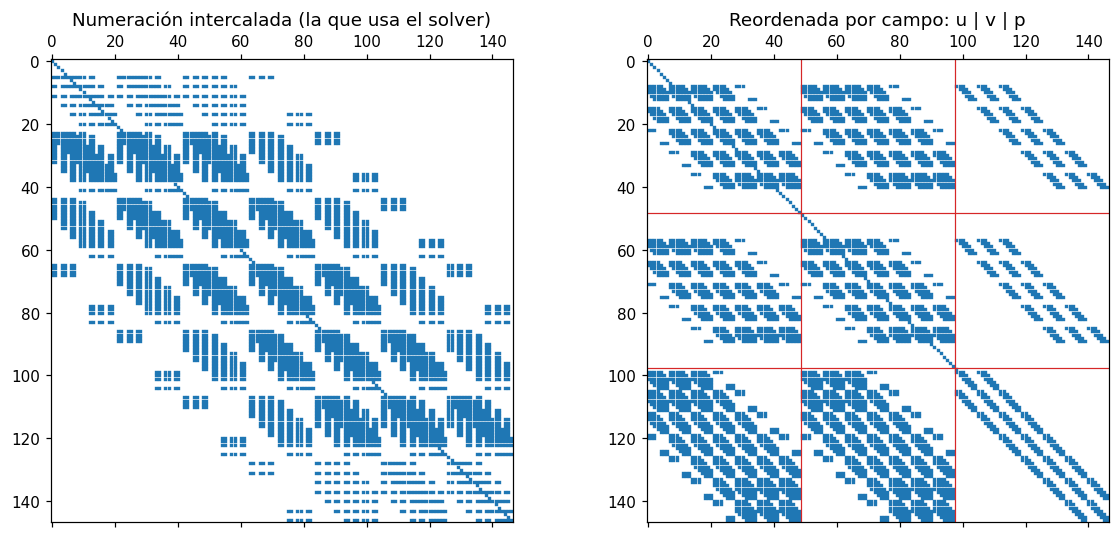

Bloque presión-presión: 354 entradas no nulas; diagonal mínima = 4.293e-02 (> 0 por PSPG)


In [10]:
small = Mesh(); small.generate2DMesh((1, 1), (6, 6), ElementType.quadrilateral)
demo = Model(name='demo', dim=2, mesh=small, mat=material('fluido', miu=mu, rho=rho), psc=ff)
demo.physics.setInertia(True)
demo.physics.addBC_VelocityEdges(small.boundary_edges(lambda x, y: y > 1 - 1e-9), (1.0, 0.0))
demo.physics.addBC_NoSlipEdges(small.boundary_edges(lambda x, y: y < 1e-9 or x < 1e-9 or x > 1 - 1e-9))
demo.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
demo.physics.initField('u', lambda x, y: (y ** 2, -x * y))          # un estado cualquiera con velocidad

J_demo, _ = demo._system().residual_and_tangent(demo._state())
lay = demo.layout
order = np.concatenate([lay.dofs('u')[:, 0], lay.dofs('u')[:, 1], lay.dofs('p')[:, 0]])
nn = small.getNoN()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].spy(J_demo, markersize=1.2); axes[0].set_title('Numeración intercalada (la que usa el solver)')
axes[1].spy(J_demo[order][:, order], markersize=1.2); axes[1].set_title('Reordenada por campo: u | v | p')
for k in (1, 2):
    axes[1].axhline(k * nn - 0.5, color='tab:red', lw=0.8); axes[1].axvline(k * nn - 0.5, color='tab:red', lw=0.8)
for ax in axes:
    ax.grid(False)
plt.tight_layout(); plt.show()

Jp = J_demo[order][:, order].tocsr()
free_p = ~demo._system().is_dirichlet[lay.dofs('p')[:, 0]]
block_pp = Jp[2 * nn:, 2 * nn:][free_p][:, free_p]
print(f"Bloque presión-presión: {block_pp.nnz} entradas no nulas; diagonal mínima = {block_pp.diagonal().min():.3e} (> 0 por PSPG)")

Las filas que parecen vacías son las incógnitas con condición de Dirichlet (velocidades del contorno): en ellas la fila es
la identidad. Los bloques fuera de la diagonal ($J_{up}$, $J_{pu}$) son el acoplamiento velocidad–presión; el bloque
$J_{pp}$ existe solo por la estabilización PSPG.

### 8.4 El lazo de Newton, paso a paso

`model.solve()` ejecuta este lazo internamente. Aquí se reproduce a mano, con las mismas piezas públicas del `System`
(`residual_and_tangent`), en una malla de $32 \times 32$, partiendo de **fluido en reposo**:

1. $J, R \leftarrow$ `system.residual_and_tangent(x)`
2. Resolver $J\,\Delta x = -R$
3. $x \leftarrow x + \Delta x$ (el solver real añade una búsqueda de línea por si el paso completo empeora el residuo)

La convergencia es casi **cuadrática**: el número de cifras correctas se duplica en cada iteración cerca de la solución. No es
exactamente cuadrática porque la tangente omite la derivada de $\tau$ respecto a la velocidad.

iter        ||R||       ||dx||
   0    5.568e+00    9.875e+00
   1    1.519e-02    2.806e+00
   2    1.656e-03    3.779e-01
   3    2.367e-05    4.139e-03
   4    1.852e-08    1.126e-06
   5    2.685e-11    1.154e-09
   6    6.099e-14   convergido


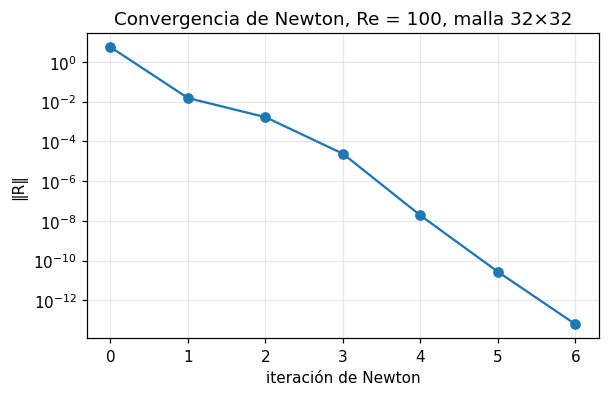

In [11]:
mesh32 = Mesh(); mesh32.generate2DMesh((1, 1), (32, 32), ElementType.quadrilateral)
m32 = Model(name='newton', dim=2, mesh=mesh32, mat=material('fluido', miu=mu, rho=rho), psc=ff)
m32.physics.setInertia(True)
m32.physics.addBC_VelocityEdges(mesh32.boundary_edges(lambda x, y: y > 1 - 1e-9), (1.0, 0.0))
m32.physics.addBC_NoSlipEdges(mesh32.boundary_edges(lambda x, y: y < 1e-9 or x < 1e-9 or x > 1 - 1e-9))
m32.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
m32.physics.initField('u', 0.0)

sys32 = m32._system()
x = m32._state()
history = []
print(f"{'iter':>4} {'||R||':>12} {'||dx||':>12}")
for it in range(10):
    J, R = sys32.residual_and_tangent(x)
    history.append(np.linalg.norm(R))
    if history[-1] < 1e-12 * max(history[0], 1.0):
        print(f"{it:>4} {history[-1]:12.3e}   convergido"); break
    dx = spla.spsolve(J.tocsc(), -R)
    print(f"{it:>4} {history[-1]:12.3e} {np.linalg.norm(dx):12.3e}")
    x = x + dx

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(history, 'o-'); ax.set_xlabel('iteración de Newton'); ax.set_ylabel('‖R‖')
ax.set_title('Convergencia de Newton, Re = 100, malla 32×32'); plt.show()

## 9. Solución a Re = 100

Ahora sí, `model.solve()` en la malla de $64 \times 64$. Al terminar:

| Atributo | Contenido |
|---|---|
| `model.sol['u']` | Velocidad nodal, forma `(nodos, 2)` |
| `model.sol['p']` | Presión nodal |
| `model.newton_iterations` | Iteraciones de Newton del último solve |
| `flow.var[...]` | Los campos también quedan guardados en la física: son el **punto de partida** del siguiente solve |

In [12]:
start = time.perf_counter()
model.solve()
elapsed = time.perf_counter() - start

u, p = model.sol['u'], model.sol['p']
print(f"Resuelto en {elapsed:.1f} s con {model.newton_iterations} iteraciones de Newton ({layout.ndof} incógnitas)")
print(f"|u| máx = {np.linalg.norm(u, axis=1).max():.4f}   p en [{p.min():.3f}, {p.max():.3f}]")

Resuelto en 2.1 s con 5 iteraciones de Newton (12675 incógnitas)
|u| máx = 1.0000   p en [-2.777, 3.925]


## 10. Resultados a Re = 100

### 10.1 Cantidades derivadas: vorticidad y función de corriente

* **Vorticidad** $\omega = \partial v/\partial x - \partial u/\partial y$: mide la rotación local. Se calcula con los gradientes
  en los puntos de Gauss (`disc.gradient`) y se lleva a los nodos con una proyección $L^2$ concentrada (`disc.project`).
* **Función de corriente** $\psi$, definida por $u = \partial\psi/\partial y$, $v = -\partial\psi/\partial x$. Sus curvas de nivel
  son las **líneas de corriente** y la diferencia de $\psi$ entre dos puntos es el caudal que pasa entre ellos. Cumple
  $-\nabla^2\psi = \omega$ con $\psi = 0$ en las paredes: es un problema de **Poisson**, que se resuelve reutilizando la física
  de calor `ht` (conductividad 1, fuente $\omega$). El mínimo de $\psi$ marca el **centro del vórtice principal**.

In [13]:
disc = model.geometry


def vorticity_and_streamfunction(u_nodal):
    grad = disc.gradient(u_nodal)                              # (nel, ngp, 2 componentes, 2 derivadas)
    omega_gp = grad[..., 1, 0] - grad[..., 0, 1]               # dv/dx - du/dy en los puntos de Gauss
    poisson = Model(name='psi', dim=2, mesh=mesh, mat=material('aux', k=1.0, rho=1.0, Cp=1.0), psc=ht)
    poisson.physics.F_const = omega_gp                         # fuente = vorticidad (arreglo en Gauss)
    poisson.physics.addBC_TemperatureEdges(mesh.boundary_edges(), 0.0)
    poisson.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.linear)
    poisson.solve()
    return disc.project(omega_gp), np.asarray(poisson.sol['T'])


def vortex_centre(psi):
    k = np.argmin(psi)
    return xy[k, 0], xy[k, 1], psi[k]


omega, psi = vorticity_and_streamfunction(u)
xc, yc, psi_min = vortex_centre(psi)
gx, gy, gpsi = GHIA_VORTEX[100.0]
print(f"Vórtice principal: (x, y) = ({xc:.4f}, {yc:.4f}), psi = {psi_min:.5f}")
print(f"Ghia et al.:       (x, y) = ({gx:.4f}, {gy:.4f}), psi = {gpsi:.5f}")

Vórtice principal: (x, y) = (0.6094, 0.7344), psi = -0.10361
Ghia et al.:       (x, y) = (0.6172, 0.7344), psi = -0.10342


### 10.2 Campos de velocidad, presión y vorticidad

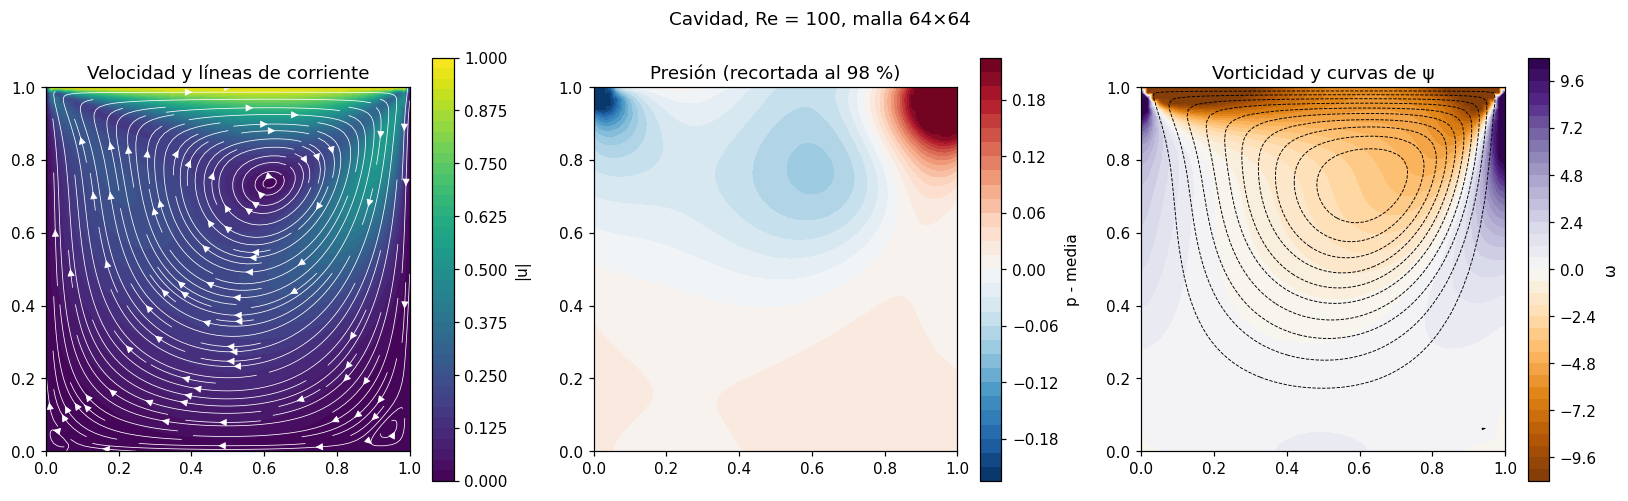

In [14]:
triang = mtri.Triangulation(xy[:, 0], xy[:, 1])
grid = np.linspace(0, 1, 201)
GX, GY = np.meshgrid(grid, grid)


def field_plots(u, p, omega, psi, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    speed = np.linalg.norm(u, axis=1)
    cs = axes[0].tricontourf(triang, speed, levels=40, cmap='viridis')
    UX = mtri.LinearTriInterpolator(triang, u[:, 0])(GX, GY); UY = mtri.LinearTriInterpolator(triang, u[:, 1])(GX, GY)
    axes[0].streamplot(GX, GY, UX, UY, color='w', density=1.6, linewidth=0.5)
    fig.colorbar(cs, ax=axes[0], label='|u|'); axes[0].set_title('Velocidad y líneas de corriente')

    p_centered = p - p.mean()
    lim = np.percentile(np.abs(p_centered), 98)
    cs = axes[1].tricontourf(triang, np.clip(p_centered, -lim, lim), levels=40, cmap='RdBu_r')
    fig.colorbar(cs, ax=axes[1], label='p - media'); axes[1].set_title('Presión (recortada al 98 %)')

    lim = np.percentile(np.abs(omega), 97)
    cs = axes[2].tricontourf(triang, np.clip(omega, -lim, lim), levels=40, cmap='PuOr')
    axes[2].tricontour(triang, psi, levels=np.r_[np.linspace(psi.min(), 0, 12)[:-1], [1e-5, 1e-4, 5e-4]],
                       colors='k', linewidths=0.6)
    fig.colorbar(cs, ax=axes[2], label='ω'); axes[2].set_title('Vorticidad y curvas de ψ')
    for ax in axes:
        ax.set_aspect('equal'); ax.grid(False); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    fig.suptitle(title); plt.tight_layout(); plt.show()


field_plots(u, p, omega, psi, f'Cavidad, Re = {Re:.0f}, malla {n}×{n}')

**Lectura de los campos.**

* El fluido gira en **sentido horario**: la tapa lo arrastra a la derecha, baja por la pared derecha y vuelve por abajo.
  A Re = 100 el centro del vórtice está **desplazado hacia la derecha y arriba** respecto al centro geométrico: es el efecto
  de la inercia (en Stokes estaría en $x = 0.5$, por simetría).
* La **presión** es muy alta en la esquina superior derecha (el fluido choca contra la pared) y muy baja en la superior
  izquierda (el fluido se separa de la pared). En las esquinas de la tapa la presión es **singular** (tiende a infinito al
  refinar), por eso se recorta la escala.
* La **vorticidad** es máxima en la capa límite bajo la tapa y casi uniforme dentro del vórtice principal. Las curvas de
  $\psi$ positivas (pequeñas) en las esquinas inferiores marcan los **vórtices secundarios** de Moffatt, que giran al revés.

### 10.3 Comparación con Ghia et al. (1982)

Se interpolan $u$ a lo largo de $x = 0.5$ y $v$ a lo largo de $y = 0.5$ en los puntos de la tabla de referencia.

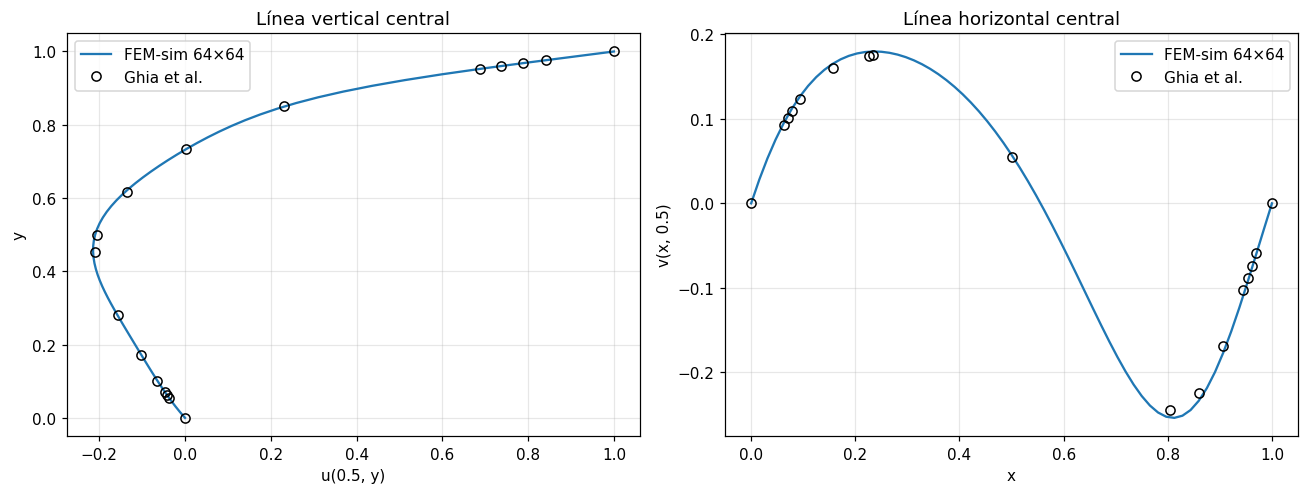

Diferencia máxima con Ghia: u 0.0057,  v 0.0094  (velocidad de la tapa = 1)


In [15]:
def centerlines(u):
    vertical = np.abs(xy[:, 0] - 0.5) < 1e-9
    horizontal = np.abs(xy[:, 1] - 0.5) < 1e-9
    ov, oh = np.argsort(xy[vertical, 1]), np.argsort(xy[horizontal, 0])
    return (xy[vertical, 1][ov], u[vertical, 0][ov]), (xy[horizontal, 0][oh], u[horizontal, 1][oh])


(yv, u_v), (xh, v_h) = centerlines(u)
err_u = np.interp(GHIA_U[:, 0], yv, u_v) - GHIA_U[:, 1]
err_v = np.interp(GHIA_V[:, 0], xh, v_h) - GHIA_V[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(u_v, yv, label=f'FEM-sim {n}×{n}'); axes[0].plot(GHIA_U[:, 1], GHIA_U[:, 0], 'ko', mfc='none', label='Ghia et al.')
axes[0].set_xlabel('u(0.5, y)'); axes[0].set_ylabel('y'); axes[0].legend(); axes[0].set_title('Línea vertical central')
axes[1].plot(xh, v_h, label=f'FEM-sim {n}×{n}'); axes[1].plot(GHIA_V[:, 0], GHIA_V[:, 1], 'ko', mfc='none', label='Ghia et al.')
axes[1].set_xlabel('x'); axes[1].set_ylabel('v(x, 0.5)'); axes[1].legend(); axes[1].set_title('Línea horizontal central')
plt.tight_layout(); plt.show()

print(f"Diferencia máxima con Ghia: u {np.abs(err_u).max():.4f},  v {np.abs(err_v).max():.4f}  (velocidad de la tapa = 1)")

## 11. Continuación en el número de Reynolds: Re = 400 y 1000

A Re alto, Newton puede no converger si parte de un estado lejano. La técnica estándar es la **continuación**: resolver una
secuencia de Reynolds crecientes, usando cada solución como punto de partida de la siguiente. En FEM-sim es automático:
los campos de la física conservan la última solución, así que basta con cambiar la viscosidad y volver a llamar a `solve()`.

In [16]:
results = {100.0: dict(u=u.copy(), p=p.copy(), omega=omega, psi=psi, its=model.newton_iterations, time=elapsed)}

for Re_k in (400.0, 1000.0):
    flow.setViscosity(rho * U_lid * L / Re_k)       # el estado anterior sigue en flow.var: continuación
    start = time.perf_counter()
    model.solve()
    elapsed_k = time.perf_counter() - start
    om_k, psi_k = vorticity_and_streamfunction(model.sol['u'])
    results[Re_k] = dict(u=model.sol['u'].copy(), p=model.sol['p'].copy(), omega=om_k, psi=psi_k,
                         its=model.newton_iterations, time=elapsed_k)
    print(f"Re = {Re_k:6.0f}: {model.newton_iterations} iteraciones de Newton, {elapsed_k:.1f} s")

Re =    400: 5 iteraciones de Newton, 1.7 s
Re =   1000: 7 iteraciones de Newton, 2.5 s


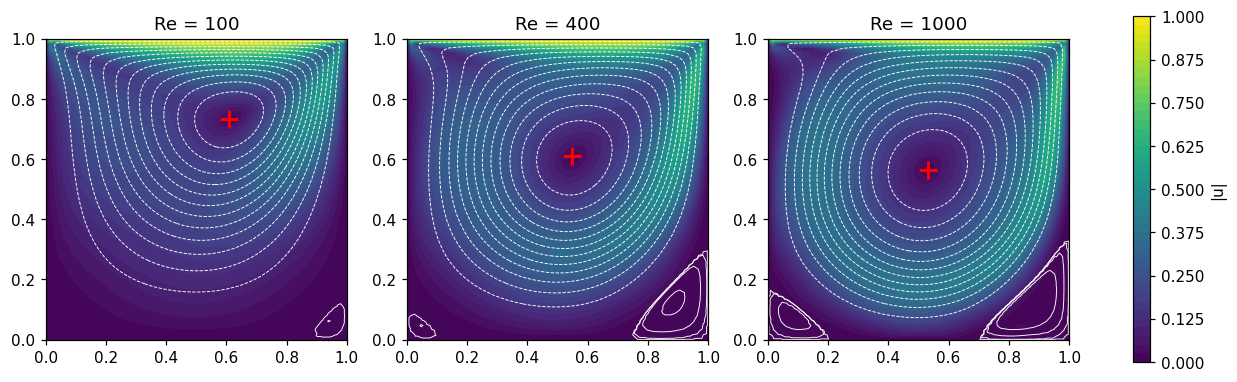

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (Re_k, res) in zip(axes, results.items()):
    speed = np.linalg.norm(res['u'], axis=1)
    cs = ax.tricontourf(triang, speed, levels=40, cmap='viridis')
    ax.tricontour(triang, res['psi'], levels=np.r_[np.linspace(res['psi'].min(), 0, 14)[:-1], [1e-6, 1e-5, 1e-4, 5e-4]],
                  colors='w', linewidths=0.6)
    xc, yc, _ = vortex_centre(res['psi'])
    ax.plot(xc, yc, 'r+', ms=12, mew=2)
    ax.set_title(f'Re = {Re_k:.0f}'); ax.set_aspect('equal'); ax.grid(False)
fig.colorbar(cs, ax=axes, label='|u|', shrink=0.85)
plt.show()

Al subir el Reynolds el vórtice principal **baja hacia el centro** y se hace casi circular, su interior gira como un sólido
rígido, y los **vórtices secundarios** de las esquinas inferiores crecen (el derecho más que el izquierdo). La cruz roja es el
mínimo de $\psi$.

## 12. Verificación con una solución exacta: el flujo de Kovasznay

La comparación con Ghia es una **validación** (contra otro cálculo). Para una **verificación** estricta del código hace falta
una solución exacta de las ecuaciones completas. Kovasznay (1948) encontró una que reproduce la estela detrás de una rejilla:

$$
u = 1 - e^{\lambda x}\cos 2\pi y,\qquad v = \frac{\lambda}{2\pi}\, e^{\lambda x}\sin 2\pi y,\qquad
p = \tfrac12\big(1 - e^{2\lambda x}\big),\qquad \lambda = \frac{\mathrm{Re}}{2} - \sqrt{\frac{\mathrm{Re}^2}{4} + 4\pi^2}.
$$

Se resuelve en $[-0.5, 1] \times [-0.5, 1.5]$ con Re = 40: velocidad exacta en tres lados y la **tracción exacta**
$\boldsymbol\sigma\cdot\mathbf{n}$ en la salida ($x = 1$), en mallas cada vez más finas. Si el método es correcto, el error debe
bajar como $h^2$ (Q1: orden 2 en velocidad).

       h    error u  orden    error p  orden  Newton
  0.1875   7.08e-02          3.07e-01              7
  0.0938   1.09e-02   2.69   8.12e-02   1.92       6
  0.0469   3.34e-03   1.71   2.13e-02   1.93       5
  0.0234   9.03e-04   1.89   5.18e-03   2.04       5


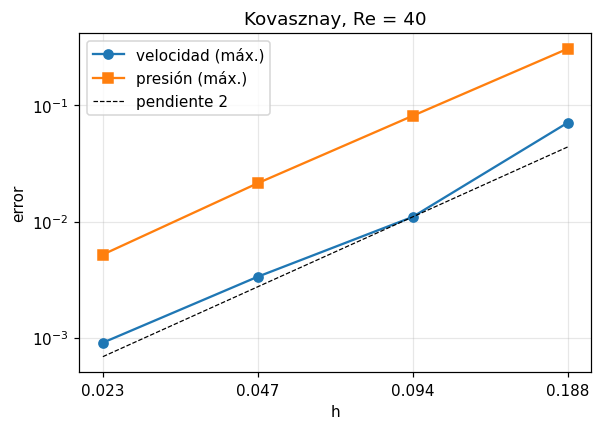

In [18]:
def kovasznay(Re_k):
    lam = Re_k / 2 - np.sqrt(Re_k ** 2 / 4 + 4 * np.pi ** 2)
    k2 = 2 * np.pi
    mu_k = 1.0 / Re_k
    U = lambda x, y: np.stack(np.broadcast_arrays(1 - np.exp(lam * x) * np.cos(k2 * y),
                                                  lam / k2 * np.exp(lam * x) * np.sin(k2 * y)), axis=-1)
    P = lambda x, y: 0.5 * (1 - np.exp(2 * lam * x))

    def traction(x, y):                       # sigma . n con n = (1, 0)
        e = np.exp(lam * x)
        ux, uy, vx = -lam * e * np.cos(k2 * y), k2 * e * np.sin(k2 * y), lam ** 2 / k2 * e * np.sin(k2 * y)
        return (-P(x, y) + 2 * mu_k * ux, mu_k * (uy + vx))
    return U, P, traction, mu_k


U_ex, P_ex, traction_ex, mu_k = kovasznay(40.0)
rows = []
for nk in (8, 16, 32, 64):
    mk = Mesh(); mk.generate2DMesh((1.5, 2.0), (nk, int(nk * 4 / 3)), ElementType.quadrilateral)
    for node in mk.NL:
        node.coor = (node.coor[0] - 0.5, node.coor[1] - 0.5)
    kov = Model(name='kovasznay', dim=2, mesh=mk, mat=material('fluido', miu=mu_k, rho=1.0), psc=ff)
    kov.physics.setInertia(True)
    kov.physics.addBC_VelocityEdges(mk.boundary_edges(lambda x, y: x < 1 - 1e-9), lambda x, y: tuple(U_ex(x, y)))
    kov.physics.addBC_TractionEdges(mk.boundary_edges(lambda x, y: x > 1 - 1e-9), traction_ex)
    kov.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
    kov.solve()
    xk = np.array([nd.coor for nd in mk.NL])
    rows.append((1.5 / nk, np.abs(kov.sol['u'] - U_ex(xk[:, 0], xk[:, 1])).max(),
                 np.abs(kov.sol['p'] - P_ex(xk[:, 0], xk[:, 1])).max(), kov.newton_iterations))

rows = np.array(rows)
print(f"{'h':>8} {'error u':>10} {'orden':>6} {'error p':>10} {'orden':>6} {'Newton':>7}")
for i, (h, eu, ep, its) in enumerate(rows):
    ru = '' if i == 0 else f"{np.log2(rows[i - 1, 1] / eu):.2f}"
    rp = '' if i == 0 else f"{np.log2(rows[i - 1, 2] / ep):.2f}"
    print(f"{h:8.4f} {eu:10.2e} {ru:>6} {ep:10.2e} {rp:>6} {int(its):>7}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(rows[:, 0], rows[:, 1], 'o-', label='velocidad (máx.)')
ax.loglog(rows[:, 0], rows[:, 2], 's-', label='presión (máx.)')
ax.loglog(rows[:, 0], rows[1, 1] * (rows[:, 0] / rows[1, 0]) ** 2, 'k--', lw=0.8, label='pendiente 2')
ax.set_xticks(rows[:, 0], [f'{h:.3f}' for h in rows[:, 0]]); ax.minorticks_off()
ax.set_xlabel('h'); ax.set_ylabel('error'); ax.legend(); ax.set_title('Kovasznay, Re = 40'); plt.show()

## 13. Presentación de resultados

### 13.1 Resumen cuantitativo

In [19]:
print(f"{'Re':>6} | {'Newton':>6} | {'tiempo':>7} | {'u_min (x=0.5)':>14} | {'centro del vórtice (FEM-sim)':>29} | {'centro (Ghia)':>16} | {'psi_min':>9} | {'psi Ghia':>9}")
print('-' * 120)
summary = []
for Re_k, res in results.items():
    (yv_k, u_k), _ = centerlines(res['u'])
    xc, yc, pm = vortex_centre(res['psi'])
    gx, gy, gp = GHIA_VORTEX[Re_k]
    summary.append((Re_k, res['its'], u_k.min(), xc, yc, pm, gp))
    print(f"{Re_k:6.0f} | {res['its']:6d} | {res['time']:5.1f} s | {u_k.min():14.4f} | ({xc:.4f}, {yc:.4f}){'':>13} | "
          f"({gx:.4f}, {gy:.4f}) | {pm:9.5f} | {gp:9.5f}")
h_ = 1.0 / n
print(f"\nResolución de la malla: h = {h_:.4f}; el centro del vórtice se localiza en un nodo (precisión ±h/2 = ±{h_ / 2:.4f}).")

    Re | Newton |  tiempo |  u_min (x=0.5) |  centro del vórtice (FEM-sim) |    centro (Ghia) |   psi_min |  psi Ghia
------------------------------------------------------------------------------------------------------------------------
   100 |      5 |   2.1 s |        -0.2143 | (0.6094, 0.7344)              | (0.6172, 0.7344) |  -0.10361 |  -0.10342
   400 |      5 |   1.7 s |        -0.3305 | (0.5469, 0.6094)              | (0.5547, 0.6055) |  -0.11447 |  -0.11391
  1000 |      7 |   2.5 s |        -0.3925 | (0.5312, 0.5625)              | (0.5313, 0.5625) |  -0.12010 |  -0.11793

Resolución de la malla: h = 0.0156; el centro del vórtice se localiza en un nodo (precisión ±h/2 = ±0.0078).


### 13.2 Figura de síntesis

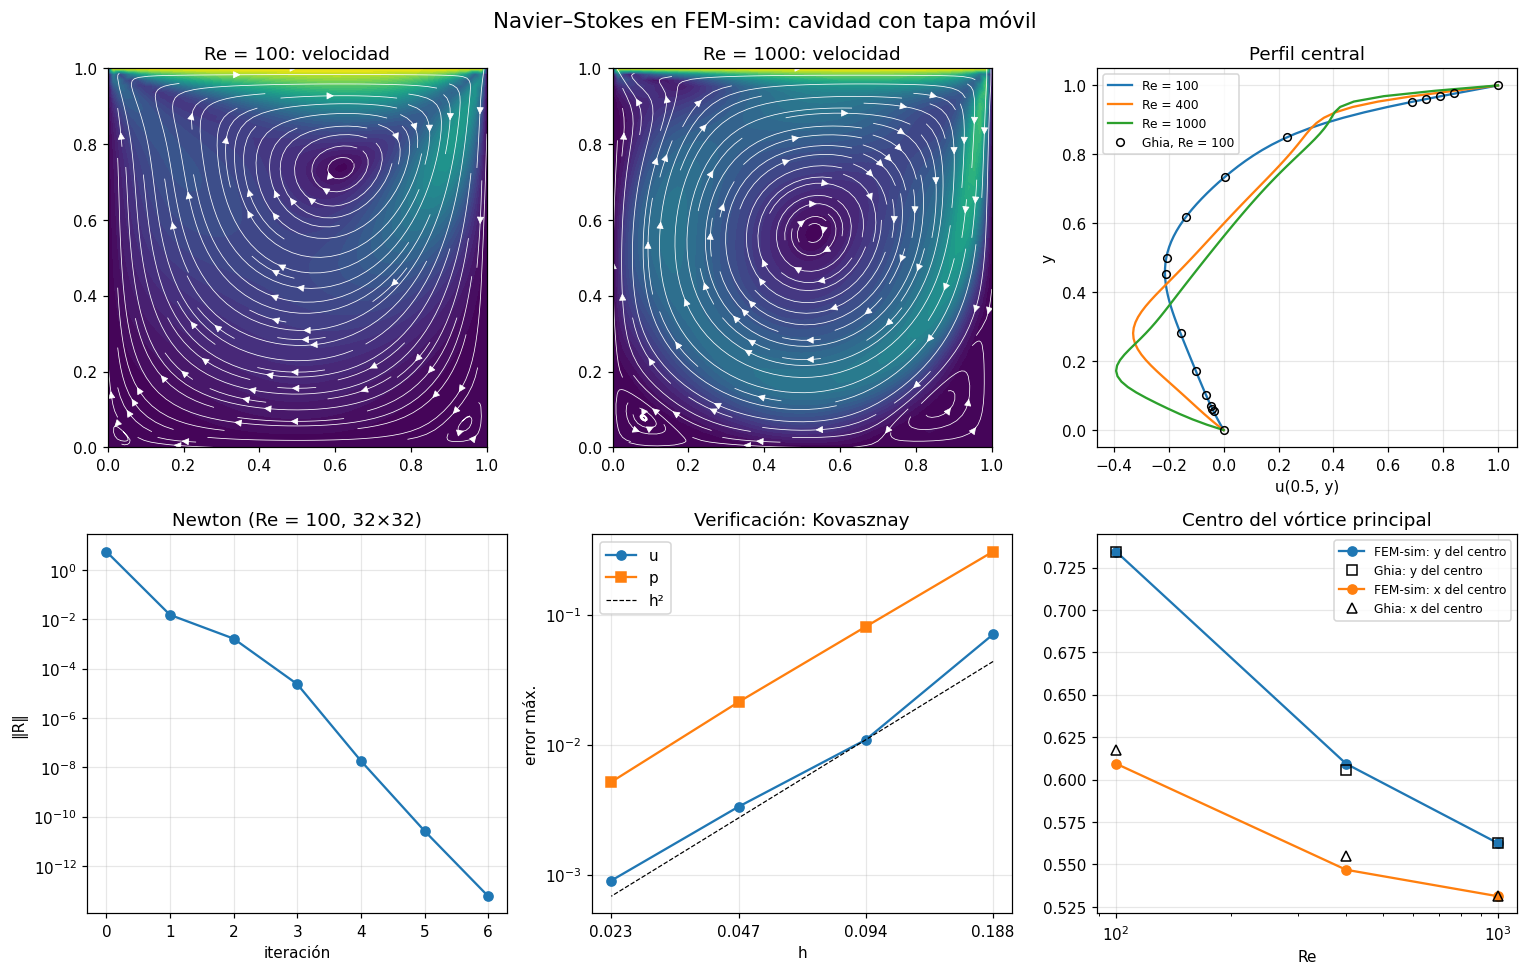

In [20]:
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 3)

ax = fig.add_subplot(gs[0, 0])
res = results[100.0]
cs = ax.tricontourf(triang, np.linalg.norm(res['u'], axis=1), levels=40, cmap='viridis')
UX = mtri.LinearTriInterpolator(triang, res['u'][:, 0])(GX, GY); UY = mtri.LinearTriInterpolator(triang, res['u'][:, 1])(GX, GY)
ax.streamplot(GX, GY, UX, UY, color='w', density=1.3, linewidth=0.5)
ax.set_title('Re = 100: velocidad'); ax.set_aspect('equal'); ax.grid(False); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = fig.add_subplot(gs[0, 1])
res = results[1000.0]
cs = ax.tricontourf(triang, np.linalg.norm(res['u'], axis=1), levels=40, cmap='viridis')
UX = mtri.LinearTriInterpolator(triang, res['u'][:, 0])(GX, GY); UY = mtri.LinearTriInterpolator(triang, res['u'][:, 1])(GX, GY)
ax.streamplot(GX, GY, UX, UY, color='w', density=1.3, linewidth=0.5)
ax.set_title('Re = 1000: velocidad'); ax.set_aspect('equal'); ax.grid(False); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = fig.add_subplot(gs[0, 2])
for Re_k, res in results.items():
    (yv_k, u_k), _ = centerlines(res['u'])
    ax.plot(u_k, yv_k, label=f'Re = {Re_k:.0f}')
ax.plot(GHIA_U[:, 1], GHIA_U[:, 0], 'ko', mfc='none', ms=5, label='Ghia, Re = 100')
ax.set_xlabel('u(0.5, y)'); ax.set_ylabel('y'); ax.legend(fontsize=8); ax.set_title('Perfil central')

ax = fig.add_subplot(gs[1, 0])
ax.semilogy(history, 'o-'); ax.set_xlabel('iteración'); ax.set_ylabel('‖R‖'); ax.set_title('Newton (Re = 100, 32×32)')

ax = fig.add_subplot(gs[1, 1])
ax.loglog(rows[:, 0], rows[:, 1], 'o-', label='u'); ax.loglog(rows[:, 0], rows[:, 2], 's-', label='p')
ax.loglog(rows[:, 0], rows[1, 1] * (rows[:, 0] / rows[1, 0]) ** 2, 'k--', lw=0.8, label='h²')
ax.set_xticks(rows[:, 0], [f'{h:.3f}' for h in rows[:, 0]]); ax.minorticks_off()
ax.set_xlabel('h'); ax.set_ylabel('error máx.'); ax.legend(); ax.set_title('Verificación: Kovasznay')

ax = fig.add_subplot(gs[1, 2])
Re_list = [s[0] for s in summary]
ax.plot(Re_list, [s[4] for s in summary], 'o-', label='FEM-sim: y del centro')
ax.plot(Re_list, [GHIA_VORTEX[r][1] for r in Re_list], 'ks', mfc='none', label='Ghia: y del centro')
ax.plot(Re_list, [s[3] for s in summary], 'o-', label='FEM-sim: x del centro')
ax.plot(Re_list, [GHIA_VORTEX[r][0] for r in Re_list], 'k^', mfc='none', label='Ghia: x del centro')
ax.set_xscale('log'); ax.set_xlabel('Re'); ax.legend(fontsize=8); ax.set_title('Centro del vórtice principal')

fig.suptitle('Navier–Stokes en FEM-sim: cavidad con tapa móvil', fontsize=14)
plt.tight_layout(); plt.show()

### 13.3 Conclusiones

1. **Validación frente a la literatura.** Con una malla de $64 \times 64$ (Ghia usó $129 \times 129$), los perfiles de velocidad
   a lo largo de las líneas centrales difieren de Ghia et al. como máximo **0.006 en $u$ y 0.009 en $v$** (con la tapa a
   velocidad 1). El centro del vórtice principal coincide **dentro de un nodo** a Re = 100, 400 y 1000, y el valor de
   $\psi_{min}$ difiere 0.2 %, 0.5 % y 1.8 %. A Re = 1000 la diferencia es mayor porque las capas límite son más delgadas
   y la malla uniforme las resuelve peor; las referencias modernas más finas dan $\psi_{min} \approx -0.1189$, entre
   ambos valores.
2. **Verificación con solución exacta.** En el flujo de Kovasznay el error de velocidad baja con orden **≈ 1.9** y el de presión
   con orden **≈ 2** al refinar: lo esperado para elementos bilineales. El código resuelve correctamente las ecuaciones
   completas (convección, viscosidad, presión y la estabilización consistente).
3. **Solver.** Newton converge en **5 a 7 iteraciones**, con el residuo bajando varios órdenes por iteración al final
   (convergencia superlineal). La continuación en Re (100 → 400 → 1000) mantiene ese número de iteraciones.
4. **Costo.** Cada Reynolds tarda unos **2 s** para 12 675 incógnitas en un portátil: el problema es pequeño para un solver
   directo.
5. **Física.** Al aumentar el Reynolds el vórtice principal migra de $(0.61, 0.73)$ hacia el centro $(0.53, 0.56)$, la
   vorticidad se concentra en capas límite delgadas y crecen los vórtices secundarios de las esquinas inferiores.

### 13.4 Límites del método actual

| Límite | Consecuencia | Previsto en |
|---|---|---|
| Elementos de igual orden (Q1/Q1, P1/P1) estabilizados | La presión converge más lento que la velocidad ($O(h)$ en norma máxima, $O(h^{1.5})$ en media cuadrática) | Etapa 17: Taylor–Hood |
| Esquinas singulares de la tapa | La presión no converge en esas esquinas (es infinita en el problema continuo) | Propio del problema |
| Re alto | Newton necesita continuación; por encima de Re ≈ 7500 la cavidad deja de tener solución estacionaria estable | Etapa 14 (transitorio) |
| Transitorio con inercia | Las masas estabilizadas se congelan al inicio del solve | Etapa 14 |
| Viscosidad constante | Fluidos no newtonianos y dependientes de la temperatura | Etapa 12 |

## 14. Exportación a ParaView

`model.exportVTK(base)` escribe un archivo `.vtu` con los campos nodales (la velocidad como vector de 3 componentes). Se le
pueden añadir campos derivados a `model.sol` antes de exportar.

In [21]:
model.sol['vorticity'] = results[1000.0]['omega']
model.sol['streamfunction'] = results[1000.0]['psi']
files = model.exportVTK(os.path.join('resultados_vtk', 'cavidad_cuaderno'))
print("Escrito:", files)
print("En ParaView: abrir el .vtu, aplicar 'Glyph' sobre u o 'Stream Tracer' para las líneas de corriente.")

Escrito: ['resultados_vtk\\cavidad_cuaderno.vtu']
En ParaView: abrir el .vtu, aplicar 'Glyph' sobre u o 'Stream Tracer' para las líneas de corriente.


### Cómo seguir

| Quiero... | Dónde mirar |
|---|---|
| Flujo reptante (polímeros fundidos) | No llamar a `setInertia`; ver `Example_Stokes_Contraction.py` |
| Un canal con entrada y salida | `addBC_VelocityEdges(entrada, perfil)` + `addBC_OutletEdges(salida, p)`; `flow.flowRate(bordes)` mide el caudal |
| Usar la velocidad calculada para transportar calor o especies | Etapas 12 y 15 del plan (`docs/PLAN_FLUIDOS.md`) |
| Entender el código | `docs/ARQUITECTURA.md` (sección 5.2) y `Source/Physics/FluidFlow.py` (`ff.add_terms`, `FlowTerm`) |
| Ver qué está validado | `docs/ESTADO.md` y `Test/test_navier_stokes.py` |